In [1]:
import numpy as np
import h2py
import moments 
import matplotlib.pyplot as plt 
import matplotlib as mpl
import copy
import msprime
import demes 
import demesdraw
import pandas
import pickle
from matplotlib.transforms import ScaledTranslation


mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

In [2]:
# Load BLRT fits
data = []
cols = ["method", "model", "rep", "ll0", "ll1", "dll"]
for method in ("sfs", "h2"):
    for model in (0, 1, 2):
        for rep in range(500):
            fname0 = f"results/{method}_blrt_model_{model}_rep_{rep}_try_0_H0.yaml"
            fname1 = f"results/{method}_blrt_model_{model}_rep_{rep}_try_0_H1.yaml"
            ll0 = demes.load(fname0).metadata["opt_info"]["ll"]
            ll1 = demes.load(fname1).metadata["opt_info"]["ll"]
            dll = ll1 - ll0
            # Treat failures of H1 to converge with LL greater than H0 as zeros
            if dll < 0:
                dll = 0
            row = [method, model, rep, ll0, ll1, dll]
            data.append(row)
blrt_df = pandas.DataFrame(data, columns=cols)
blrt_df.to_csv("blrt_table.csv", index=0)

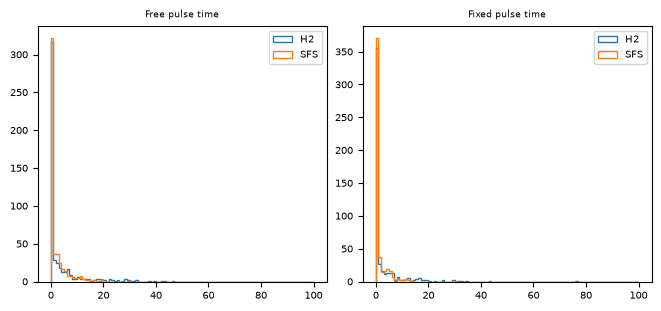

In [97]:
fig, axs = plt.subplots(1, 2, figsize=(6.5, 3), layout="constrained")

ax = axs[0]
blrt_df = pandas.read_csv("blrt_table.csv")
h2_df = blrt_df[(blrt_df["method"] == "h2") & (blrt_df["model"] == 0)]
sfs_df = blrt_df[(blrt_df["method"] == "sfs") & (blrt_df["model"] == 0)]
bins = np.linspace(0, 100, 101)
ax.hist(h2_df["dll"], histtype="step", bins=bins, label="H2")
ax.hist(sfs_df["dll"], histtype="step", bins=bins, label="SFS")
ax.set_title("Free pulse time")
ax.legend()

ax = axs[1]
blrt_df = pandas.read_csv("blrt_table.csv")
h2_df = blrt_df[(blrt_df["method"] == "h2") & (blrt_df["model"] == 1)]
sfs_df = blrt_df[(blrt_df["method"] == "sfs") & (blrt_df["model"] == 1)]
bins = np.linspace(0, 100, 101)
ax.hist(h2_df["dll"], histtype="step", bins=bins, label="H2")
ax.hist(sfs_df["dll"], histtype="step", bins=bins, label="SFS")
ax.set_title("Fixed pulse time")
ax.legend()
plt.savefig("empirical_null_distr.pdf")

In [8]:
# Load focal fits
data = []
cols = ["method", "model", "prop", "rep", "ll0", "ll1", "dll"]
for method in ("sfs", "h2"):
    for model in (0, 1, 2):
        for prop in (0, 1, 2, 5, 10):
            for rep in range(100):
                fname0 = f"results/{method}_focal_model_{model}_{prop}_rep_{rep}_try_0_H0.yaml"
                fname1 = f"results/{method}_focal_model_{model}_{prop}_rep_{rep}_try_0_H1.yaml"
                ll0 = demes.load(fname0).metadata["opt_info"]["ll"]
                ll1 = demes.load(fname1).metadata["opt_info"]["ll"]
                dll = ll1 - ll0
                # Treat failures of H1 to converge with LL greater than H0 as zeros
                if dll < 0:
                    dll = 0
                row = [method, model, prop, rep, ll0, ll1, dll]
                data.append(row)
focal_df = pandas.DataFrame(data, columns=cols)
focal_df.to_csv("focal_ll_table.csv", index=0)

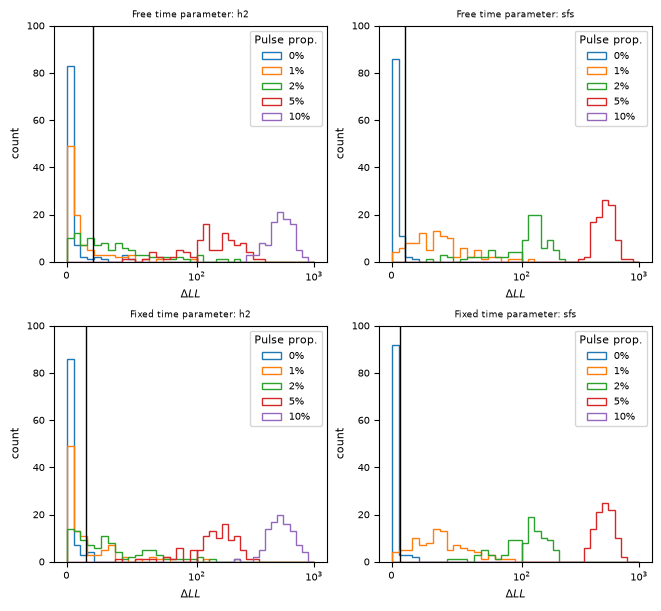

In [76]:
fig, axs = plt.subplots(2, 2, figsize=(6.5, 6), layout="constrained")
axs = axs.flat
focal_df = pandas.read_csv("focal_ll_table.csv")
blrt_df = pandas.read_csv("blrt_table.csv")
labels = ["Free time parameter", "Fixed time parameter"]
counter = 0
for model in (0, 1):
    for method in ("h2", "sfs"):
        ax = axs[counter]
        sub_blrt_df = blrt_df[(blrt_df["method"] == method) & (blrt_df["model"] == model)]
        cutoff = np.quantile(sub_blrt_df["dll"], 0.95)
        sub_df = focal_df[(focal_df["method"] == method) & (focal_df["model"] == model)]
        bins = np.concatenate([np.linspace(0, 100, 20), np.logspace(2, 3, 20)])
        for prop in (0, 1, 2, 5, 10):
            sub_sub_df = sub_df[sub_df["prop"] == prop]
            ax.hist(sub_sub_df["dll"], histtype="step", bins=bins, label=f"{prop}%")
        ax.legend(title="Pulse prop.")
        ax.set_xlabel("$\\Delta LL$")
        ax.set_ylabel("count")
        ax.set_xscale("symlog", linthresh=100)
        ax.set_title(f"{labels[model]}: {method}")
        ax.vlines(cutoff, 0, 100, color="black", lw=1)
        ax.set_ylim(0, 100)
        counter += 1
plt.savefig("ll_distr_summary.pdf")

In [5]:
# Load focal fit parameters
metadata = ["method", "model", "prop", "rep"]
for model in (0, 1, 2):
    data = []
    for method in ("sfs", "h2"):
        for prop in (0, 1, 2, 5, 10):
            for rep in range(100):
                fname = f"results/{method}_focal_model_{model}_{prop}_rep_{rep}_try_0_H1.yaml"
                ps, pnames = h2py.inference.load_params(fname, f"models/params_{model}_1.yaml")
                row = [method, model, prop, rep] + list(ps)
                data.append(row)
    param_df = pandas.DataFrame(data, columns=metadata + pnames)
    param_df.to_csv(f"focal_params_model_{model}.csv")

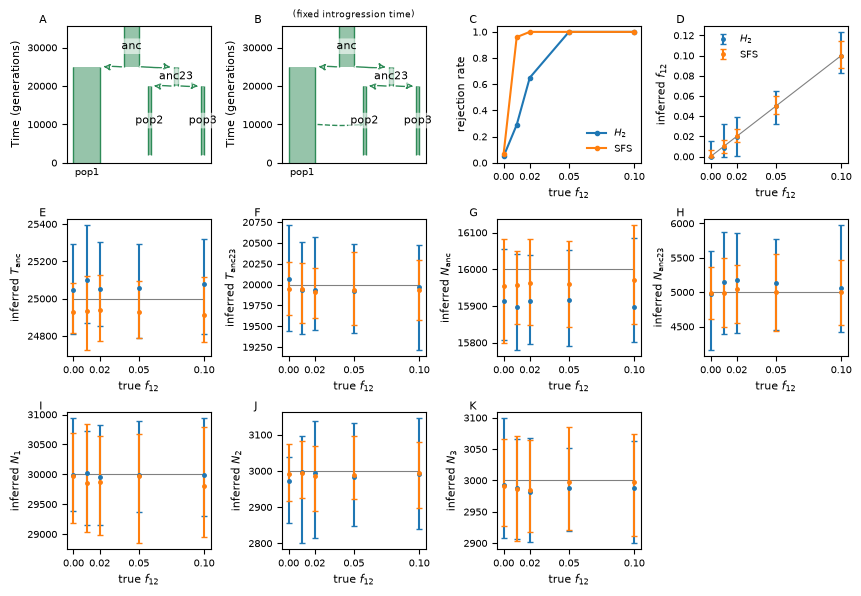

In [48]:
# Make a summary figure for model 1 [fixed time parameter]

blrt_df = pandas.read_csv("blrt_table.csv")
blrt_df = blrt_df[blrt_df["model"] == 1]
focal_df = pandas.read_csv("focal_ll_table.csv")
focal_df = focal_df[focal_df["model"] == 1]
param_df = pandas.read_csv("focal_params_model_1.csv")
props = np.array([0, 1, 2, 5, 10])

# positions for demes
positions = {
    "anc": 0,
    "anc23": 5e4,
    "pop1": -5e4,
    "pop2": 2e4,
    "pop3": 8e4,
}


def plot_model_0_0(ax):
    demesdraw.tubes(
        demes.load("models/model_0_0.yaml"),
        ax=ax,
        inf_ratio=0.30,
        colours="seagreen",
        positions=positions,
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    return


def plot_model_0_1(ax):
    demesdraw.tubes(
        demes.load("models/model_0_1.yaml"),
        ax=ax,
        inf_ratio=0.30,
        colours="seagreen",
        positions=positions,
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    return


def plot_power(ax):
    xs = np.array(props) / 100
    sub_df = blrt_df[blrt_df["method"] == "h2"]
    scores = np.array(sub_df["dll"])
    crit_val = np.quantile(scores, 0.95)
    h2_pwr = []
    for prop in props:
        sub_df = focal_df[(focal_df["method"] == "h2") & (focal_df["prop"] == prop)]
        scores = np.array(sub_df["dll"])
        pwr = np.count_nonzero(scores > crit_val) / len(scores)
        h2_pwr.append(pwr)
    ax.plot(xs, h2_pwr, marker="o", label="$H_2$", markersize=3)

    sub_df = blrt_df[blrt_df["method"] == "sfs"]
    scores = np.array(sub_df["dll"])
    crit_val = np.quantile(scores, 0.95)
    sfs_pwr = []
    for prop in props:
        sub_df = focal_df[(focal_df["method"] == "sfs") & (focal_df["prop"] == prop)]
        scores = np.array(sub_df["dll"])
        pwr = np.count_nonzero(scores > crit_val) / len(scores)
        sfs_pwr.append(pwr)
    ax.plot(xs, sfs_pwr, marker="o", label="SFS", markersize=3)
    
    ax.legend(framealpha=0)
    ax.set_ylabel("rejection rate")
    ax.set_xlabel("true $f_\\text{12}$")
    ax.set_ylim(0,)
    ax.set_xticks([0, 0.02, 0.05, 0.10])


def plot_param(ax, param, label, value):
    xs = np.array(props) / 100
    ax.hlines(value, 0, 0.1, lw=0.8, color="grey")
    # For pulse proportions.
    if np.isnan(value):
        ax.plot(xs, xs, lw=0.8, color="grey")
    h2_med = []
    h2_low = []
    h2_high = []
    for prop in props:
        sub_df = param_df[(param_df["method"] == "h2") & (param_df["prop"] == prop)]
        med = np.median(sub_df[param])
        h2_med.append(med)
        h2_low.append(med - np.quantile(sub_df[param], 0.025))
        h2_high.append(np.quantile(sub_df[param], 0.975) - med)
    sfs_med = []
    sfs_low = []
    sfs_high = []
    for prop in props:
        sub_df = param_df[(param_df["method"] == "sfs") & (param_df["prop"] == prop)]
        med = np.median(sub_df[param])
        sfs_med.append(med)
        sfs_low.append(med - np.quantile(sub_df[param], 0.025))
        sfs_high.append(np.quantile(sub_df[param], 0.975) - med)

    ax.errorbar(xs, h2_med, yerr=(h2_low, h2_high), 
                fmt=".", label="$H_2$", markersize=5, capsize=2)
    ax.errorbar(xs, sfs_med, yerr=(sfs_low, sfs_high), 
                fmt=".", label="SFS", markersize=5, capsize=2)
    #ax.legend(framealpha=0)
    ax.set_ylabel("inferred " + label)
    ax.set_xlabel("true $f_\\text{12}$")
    ax.set_xticks([0, 0.02, 0.05, 0.10])
    return
    

mosaic = "ABCD;EFGH;IJK."
fig, axs = plt.subplot_mosaic(mosaic, figsize=(8.5, 5.85), layout="constrained")


for label, ax in axs.items():
    ax.text(0.0, 1.0, label, fontsize="medium", va="bottom", transform=(
        ax.transAxes + ScaledTranslation(-20/72, +0/72, fig.dpi_scale_trans)))


plot_model_0_0(axs["A"])
axs["A"].set_ylabel("Time (generations)")
plot_model_0_1(axs["B"])
axs["B"].set_ylabel("Time (generations)")
axs["B"].set_title("(fixed introgression time)")
plot_power(axs["C"])
plot_param(axs["D"], "p12", "$f_\\text{12}$", np.nan)
axs["D"].legend(framealpha=0)
plot_param(axs["E"], "Tanc", "$T_\\text{anc}$", 25000)
plot_param(axs["F"], "Tanc23", "$T_\\text{anc23}$", 20000)
# plot_param(axs["G"], "Tpulse", "$T_\\text{pulse}$", 10000)
plot_param(axs["G"], "Nanc", "$N_\\text{anc}$", 16000)
plot_param(axs["H"], "Nanc23", "$N_\\text{anc23}$", 5e3)
plot_param(axs["I"], "N1", "$N_1$", 3e4)
plot_param(axs["J"], "N2", "$N_2$", 3e3)
plot_param(axs["K"], "N3", "$N_3$", 3e3)
plt.savefig("../../figures/BLRT_power_model_1.pdf")

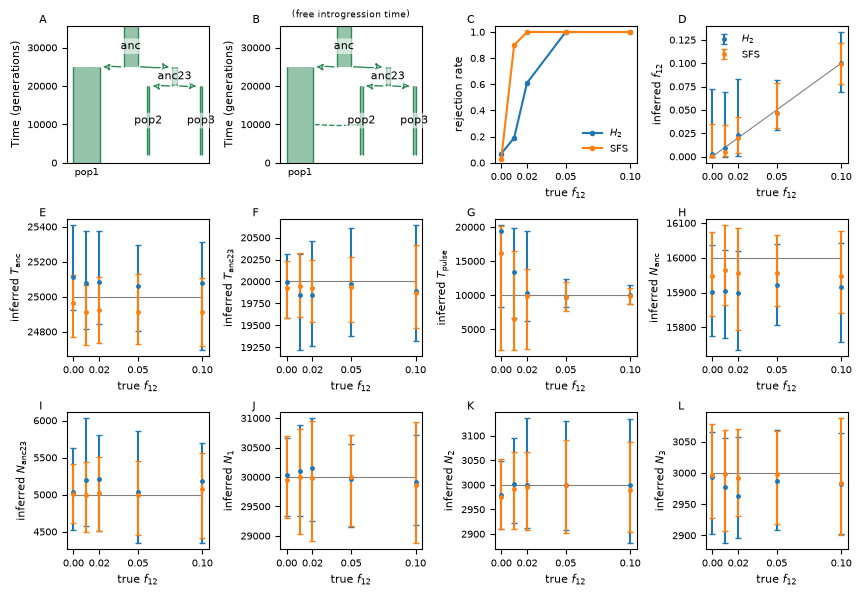

In [50]:
# Make a summary figure for model 0 [free time parameter]

blrt_df = pandas.read_csv("blrt_table.csv")
blrt_df = blrt_df[blrt_df["model"] == 0]
focal_df = pandas.read_csv("focal_ll_table.csv")
focal_df = focal_df[focal_df["model"] == 0]
param_df = pandas.read_csv("focal_params_model_0.csv")
props = np.array([0, 1, 2, 5, 10])


# positions for demes
positions = {
    "anc": 0,
    "anc23": 5e4,
    "pop1": -5e4,
    "pop2": 2e4,
    "pop3": 8e4,
}


def plot_model_0_0(ax):
    demesdraw.tubes(
        demes.load("models/model_0_0.yaml"),
        ax=ax,
        inf_ratio=0.30,
        colours="seagreen",
        positions=positions,
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    return


def plot_model_0_1(ax):
    demesdraw.tubes(
        demes.load("models/model_0_1.yaml"),
        ax=ax,
        inf_ratio=0.30,
        colours="seagreen",
        positions=positions,
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    return


def plot_power(ax):
    xs = np.array(props) / 100
    sub_df = blrt_df[blrt_df["method"] == "h2"]
    scores = np.array(sub_df["dll"])
    crit_val = np.quantile(scores, 0.95)
    h2_pwr = []
    for prop in props:
        sub_df = focal_df[(focal_df["method"] == "h2") & (focal_df["prop"] == prop)]
        scores = np.array(sub_df["dll"])
        pwr = np.count_nonzero(scores > crit_val) / len(scores)
        h2_pwr.append(pwr)
    ax.plot(xs, h2_pwr, marker="o", label="$H_2$", markersize=3)

    sub_df = blrt_df[blrt_df["method"] == "sfs"]
    scores = np.array(sub_df["dll"])
    crit_val = np.quantile(scores, 0.95)
    sfs_pwr = []
    for prop in props:
        sub_df = focal_df[(focal_df["method"] == "sfs") & (focal_df["prop"] == prop)]
        scores = np.array(sub_df["dll"])
        pwr = np.count_nonzero(scores > crit_val) / len(scores)
        sfs_pwr.append(pwr)
    ax.plot(xs, sfs_pwr, marker="o", label="SFS", markersize=3)
    
    ax.legend(framealpha=0)
    ax.set_ylabel("rejection rate")
    ax.set_xlabel("true $f_\\text{12}$")
    ax.set_ylim(0,)
    ax.set_xticks([0, 0.02, 0.05, 0.10])


def plot_param(ax, param, label, value):
    xs = np.array(props) / 100
    ax.hlines(value, 0, 0.1, lw=0.8, color="grey")
    # For pulse proportions.
    if np.isnan(value):
        ax.plot(xs, xs, lw=0.8, color="grey")
    h2_med = []
    h2_low = []
    h2_high = []
    for prop in props:
        sub_df = param_df[(param_df["method"] == "h2") & (param_df["prop"] == prop)]
        med = np.median(sub_df[param])
        h2_med.append(med)
        h2_low.append(med - np.quantile(sub_df[param], 0.025))
        h2_high.append(np.quantile(sub_df[param], 0.975) - med)
    sfs_med = []
    sfs_low = []
    sfs_high = []
    for prop in props:
        sub_df = param_df[(param_df["method"] == "sfs") & (param_df["prop"] == prop)]
        med = np.median(sub_df[param])
        sfs_med.append(med)
        sfs_low.append(med - np.quantile(sub_df[param], 0.025))
        sfs_high.append(np.quantile(sub_df[param], 0.975) - med)

    ax.errorbar(xs, h2_med, yerr=(h2_low, h2_high), 
                fmt=".", label="$H_2$", markersize=5, capsize=2)
    ax.errorbar(xs, sfs_med, yerr=(sfs_low, sfs_high), 
                fmt=".", label="SFS", markersize=5, capsize=2)
    #ax.legend(framealpha=0)
    ax.set_ylabel("inferred " + label)
    ax.set_xlabel("true $f_\\text{12}$")
    ax.set_xticks([0, 0.02, 0.05, 0.10])
    return
    

mosaic = "ABCD;EFGH;IJKL"
fig, axs = plt.subplot_mosaic(mosaic, figsize=(8.5, 5.85), layout="constrained")


for label, ax in axs.items():
    ax.text(0.0, 1.0, label, fontsize="medium", va="bottom", transform=(
        ax.transAxes + ScaledTranslation(-20/72, +0/72, fig.dpi_scale_trans)))


plot_model_0_0(axs["A"])
axs["A"].set_ylabel("Time (generations)")
plot_model_0_1(axs["B"])
axs["B"].set_ylabel("Time (generations)")
axs["B"].set_title("(free introgression time)")
plot_power(axs["C"])
plot_param(axs["D"], "p12", "$f_\\text{12}$", np.nan)
axs["D"].legend(framealpha=0)
plot_param(axs["E"], "Tanc", "$T_\\text{anc}$", 25000)
plot_param(axs["F"], "Tanc23", "$T_\\text{anc23}$", 20000)
plot_param(axs["G"], "Tpulse", "$T_\\text{pulse}$", 10000)
plot_param(axs["H"], "Nanc", "$N_\\text{anc}$", 16000)
plot_param(axs["I"], "Nanc23", "$N_\\text{anc23}$", 5e3)
plot_param(axs["J"], "N1", "$N_1$", 3e4)
plot_param(axs["K"], "N2", "$N_2$", 3e3)
plot_param(axs["L"], "N3", "$N_3$", 3e3)
plt.savefig("../../figures/BLRT_power_model_0.pdf")

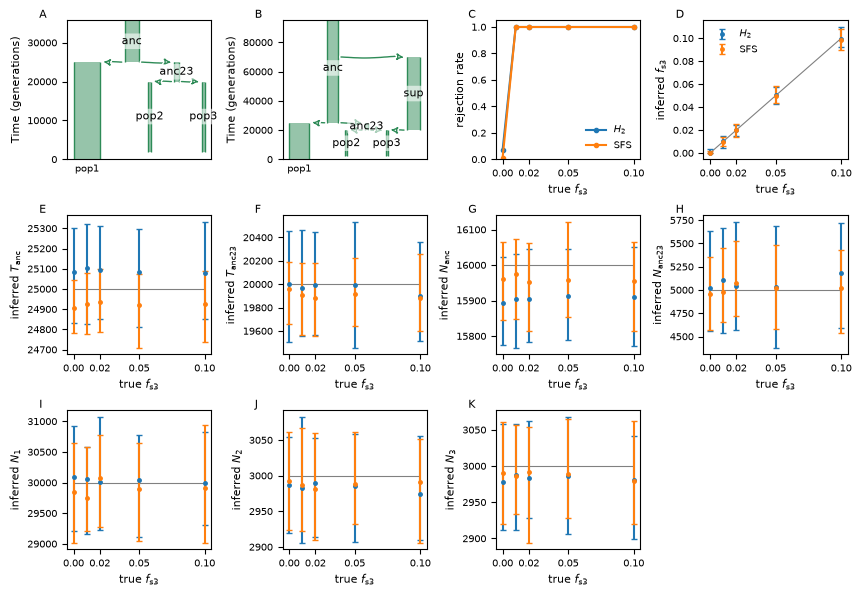

In [51]:
# Make a summary figure for model 2

blrt_df = pandas.read_csv("blrt_table.csv")
blrt_df = blrt_df[blrt_df["model"] == 2]
focal_df = pandas.read_csv("focal_ll_table.csv")
focal_df = focal_df[focal_df["model"] == 2]
param_df = pandas.read_csv("focal_params_model_2.csv")
props = np.array([0, 1, 2, 5, 10])

# positions for demes
positions = {
    "anc": 0,
    "anc23": 5e4,
    "pop1": -5e4,
    "pop2": 2e4,
    "pop3": 8e4,
    "sup": 1.2e5,
}


def plot_model_0_0(ax):
    demesdraw.tubes(
        demes.load("models/model_2_0.yaml"),
        ax=ax,
        inf_ratio=0.30,
        colours="seagreen",
        positions=positions,
    )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    return


def plot_model_0_1(ax):
    demesdraw.tubes(
        demes.load("models/model_2_1.yaml"),
        ax=ax,
        inf_ratio=0.30,
        colours="seagreen",
        positions=positions,
    )
    ax.set_ylim(None, 95000)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    return


def plot_power(ax):
    xs = np.array(props) / 100
    sub_df = blrt_df[blrt_df["method"] == "h2"]
    scores = np.array(sub_df["dll"])
    crit_val = np.quantile(scores, 0.95)
    h2_pwr = []
    for prop in props:
        sub_df = focal_df[(focal_df["method"] == "h2") & (focal_df["prop"] == prop)]
        scores = np.array(sub_df["dll"])
        pwr = np.count_nonzero(scores > crit_val) / len(scores)
        h2_pwr.append(pwr)
    ax.plot(xs, h2_pwr, marker="o", label="$H_2$", markersize=3)

    sub_df = blrt_df[blrt_df["method"] == "sfs"]
    scores = np.array(sub_df["dll"])
    crit_val = np.quantile(scores, 0.95)
    sfs_pwr = []
    for prop in props:
        sub_df = focal_df[(focal_df["method"] == "sfs") & (focal_df["prop"] == prop)]
        scores = np.array(sub_df["dll"])
        pwr = np.count_nonzero(scores > crit_val) / len(scores)
        sfs_pwr.append(pwr)
    ax.plot(xs, sfs_pwr, marker="o", label="SFS", markersize=3)
    
    ax.legend(framealpha=0)
    ax.set_ylabel("rejection rate")
    ax.set_xlabel("true $f_\\text{s3}$")
    ax.set_ylim(0,)
    ax.set_xticks([0, 0.02, 0.05, 0.10])


def plot_param(ax, param, label, value):
    xs = np.array(props) / 100
    ax.hlines(value, 0, 0.1, lw=0.8, color="grey")
    # For pulse proportions.
    if np.isnan(value):
        ax.plot(xs, xs, lw=0.8, color="grey")
    h2_med = []
    h2_low = []
    h2_high = []
    for prop in props:
        sub_df = param_df[(param_df["method"] == "h2") & (param_df["prop"] == prop)]
        med = np.median(sub_df[param])
        h2_med.append(med)
        h2_low.append(med - np.quantile(sub_df[param], 0.025))
        h2_high.append(np.quantile(sub_df[param], 0.975) - med)
    sfs_med = []
    sfs_low = []
    sfs_high = []
    for prop in props:
        sub_df = param_df[(param_df["method"] == "sfs") & (param_df["prop"] == prop)]
        med = np.median(sub_df[param])
        sfs_med.append(med)
        sfs_low.append(med - np.quantile(sub_df[param], 0.025))
        sfs_high.append(np.quantile(sub_df[param], 0.975) - med)

    ax.errorbar(xs, h2_med, yerr=(h2_low, h2_high), 
                fmt=".", label="$H_2$", markersize=5, capsize=2)
    ax.errorbar(xs, sfs_med, yerr=(sfs_low, sfs_high), 
                fmt=".", label="SFS", markersize=5, capsize=2)
    #ax.legend(framealpha=0)
    ax.set_ylabel("inferred " + label)
    ax.set_xlabel("true $f_\\text{s3}$")
    ax.set_xticks([0, 0.02, 0.05, 0.10])
    return
    

mosaic = "ABCD;EFGH;IJK."
fig, axs = plt.subplot_mosaic(mosaic, figsize=(8.5, 5.85), layout="constrained")


for label, ax in axs.items():
    ax.text(0.0, 1.0, label, fontsize="medium", va="bottom", transform=(
        ax.transAxes + ScaledTranslation(-20/72, +0/72, fig.dpi_scale_trans)))


plot_model_0_0(axs["A"])
axs["A"].set_ylabel("Time (generations)")
plot_model_0_1(axs["B"])
axs["B"].set_ylabel("Time (generations)")
plot_power(axs["C"])
plot_param(axs["D"], "ps3", "$f_\\text{s3}$", np.nan)
axs["D"].legend(framealpha=0)
plot_param(axs["E"], "Tanc", "$T_\\text{anc}$", 25000)
plot_param(axs["F"], "Tanc23", "$T_\\text{anc23}$", 20000)
# plot_param(axs["G"], "Tpulse", "$T_\\text{pulse}$", 10000)
plot_param(axs["G"], "Nanc", "$N_\\text{anc}$", 16000)
plot_param(axs["H"], "Nanc23", "$N_\\text{anc23}$", 5e3)
plot_param(axs["I"], "N1", "$N_1$", 3e4)
plot_param(axs["J"], "N2", "$N_2$", 3e3)
plot_param(axs["K"], "N3", "$N_3$", 3e3)
plt.savefig("../../figures/BLRT_power_model_2.pdf")